# Simple Autoencoder for MNIST

**Student roll number:** `24BAD099`  
**Name:** `Rithish A`  

In [1]:
# Install only if the environment does not already provide these packages.
# Uncomment the next line in Google Colab if needed.
# %pip install -q tensorflow matplotlib numpy pandas

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## Part A — Dataset preparation and preprocessing

MNIST contains 60,000 training images and 10,000 test images. Each grayscale image has shape 28 × 28. The labels are loaded for exploration, but an autoencoder does not use them during training.

In [2]:
(x_train_images, y_train), (x_test_images, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train_images.shape)
print("Training labels:", y_train.shape)
print("Testing images: ", x_test_images.shape)
print("Testing labels: ", y_test.shape)
print("Image data type:", x_train_images.dtype)
print("Pixel range before normalization:", x_train_images.min(), "to", x_train_images.max())

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images:  (10000, 28, 28)
Testing labels:  (10000,)
Image data type: uint8
Pixel range before normalization: 0 to 255


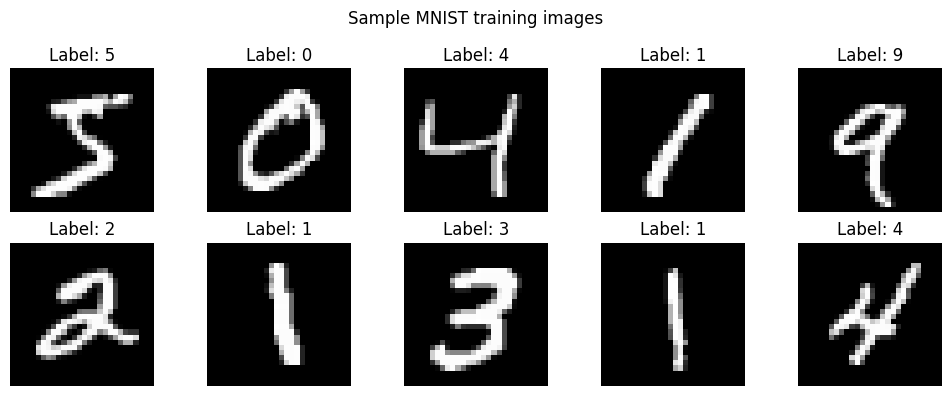

Prepared training shape: (60000, 784)
Prepared testing shape:  (10000, 784)
Pixel range after normalization: 0.0 to 1.0
Autoencoder targets are identical copies of the inputs: True


In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), x_train_images[:10], y_train[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.suptitle("Sample MNIST training images")
plt.tight_layout()
plt.show()

# Convert uint8 pixels to float32 values in [0, 1], then flatten 28 x 28 to 784.
x_train = x_train_images.astype("float32") / 255.0
x_test = x_test_images.astype("float32") / 255.0
x_train = x_train.reshape((-1, 28 * 28))
x_test = x_test.reshape((-1, 28 * 28))

print("Prepared training shape:", x_train.shape)
print("Prepared testing shape: ", x_test.shape)
print("Pixel range after normalization:", x_train.min(), "to", x_train.max())
print("Autoencoder targets are identical copies of the inputs:", np.array_equal(x_train, x_train.copy()))

## Part B — Encoder and decoder

The encoder maps 784 input values to a 32-dimensional latent vector. The decoder maps that vector back to 784 values. ReLU is used in hidden layers and sigmoid is used at the output so reconstructed pixels remain in [0, 1].

In [4]:
INPUT_DIM = 784
LATENT_DIM = 32

encoder_input = keras.Input(shape=(INPUT_DIM,), name="encoder_input")
encoded = layers.Dense(128, activation="relu", name="encoder_dense_128")(encoder_input)
latent = layers.Dense(LATENT_DIM, activation="relu", name="latent_vector")(encoded)
encoder = keras.Model(encoder_input, latent, name="encoder")

decoder_input = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
decoded_hidden = layers.Dense(128, activation="relu", name="decoder_dense_128")(decoder_input)
decoder_output = layers.Dense(INPUT_DIM, activation="sigmoid", name="reconstruction")(decoded_hidden)
decoder = keras.Model(decoder_input, decoder_output, name="decoder")

autoencoder_input = keras.Input(shape=(INPUT_DIM,), name="autoencoder_input")
autoencoder_output = decoder(encoder(autoencoder_input))
autoencoder = keras.Model(autoencoder_input, autoencoder_output, name="mnist_autoencoder")

print("ENCODER SUMMARY")
encoder.summary()
print("DECODER SUMMARY")
decoder.summary()
print("AUTOENCODER SUMMARY")
autoencoder.summary()

ENCODER SUMMARY


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_128 (Dense)       │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

## Part C — Compilation and training

Binary cross-entropy compares the original normalized pixel values with the reconstructed pixel values. The test set is supplied as validation data; it is still used with itself as the target because reconstruction, not classification, is the task.

In [5]:
autoencoder.compile(optimizer=keras.optimizers.Adam(), loss="binary_crossentropy")

history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1,
)

print("Final training loss:  ", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

Epoch 1/10



  1/235 ━━━━━━━━━━━━━━━━━━━━ 3:58 1s/step - loss: 0.6932


  8/235 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6824 


 16/235 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6528


 24/235 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6136


 33/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.5742

... (281 outputs left out)


222/235 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0960


231/235 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0960


235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0957 - val_loss: 0.0944


Final training loss:   0.09565530717372894
Final validation loss: 0.09441585093736649


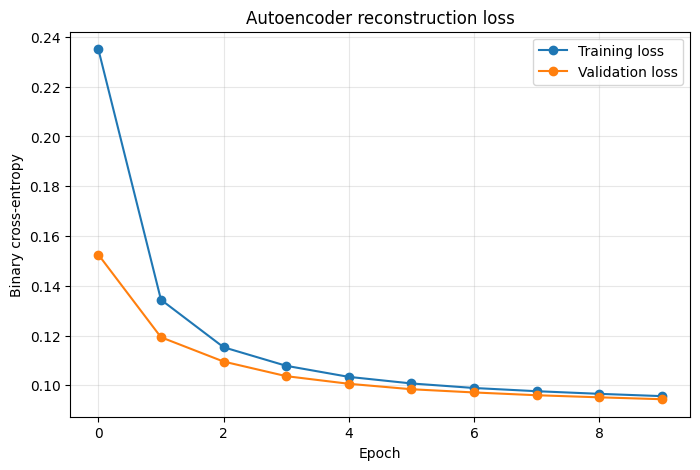

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Autoencoder reconstruction loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Part D — Dimensionality reduction, features, and reconstruction

In [7]:
latent_test = encoder.predict(x_test, batch_size=256, verbose=0)
reconstructed_test = decoder.predict(latent_test, batch_size=256, verbose=0)

print("Original input dimension:", x_test.shape[1])
print("Latent dimension:          ", latent_test.shape[1])
print("Latent feature matrix:     ", latent_test.shape)
print("Reconstructed matrix:      ", reconstructed_test.shape)
print("Test reconstruction MSE:   ", np.mean((x_test - reconstructed_test) ** 2))

Original input dimension: 784
Latent dimension:           32
Latent feature matrix:      (10000, 32)
Reconstructed matrix:       (10000, 784)
Test reconstruction MSE:    0.010717755


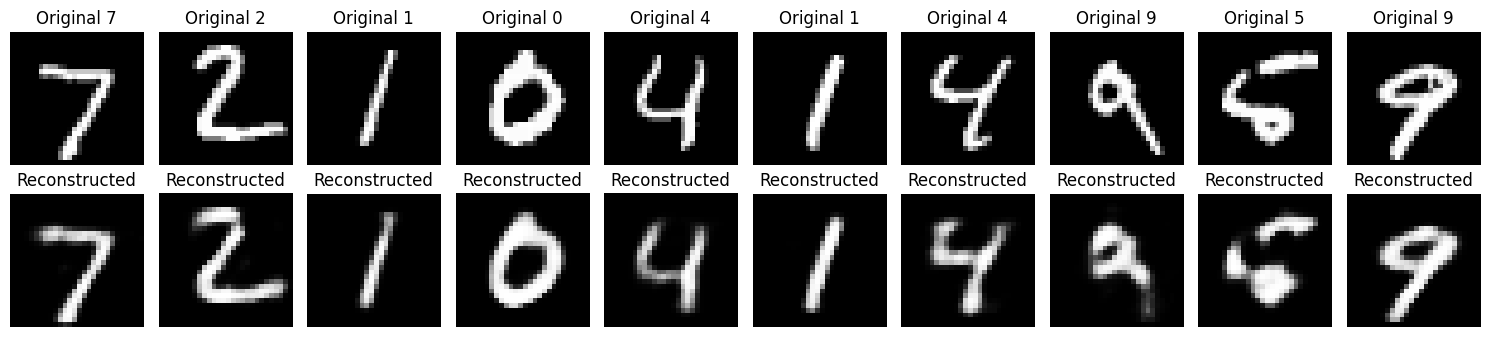

The reconstruction usually preserves the digit identity and broad strokes.
Fine details may be blurred or lost because 784 values are compressed into 32 features.


In [8]:
n_examples = 10
fig, axes = plt.subplots(2, n_examples, figsize=(15, 3.5))
for i in range(n_examples):
    axes[0, i].imshow(x_test[i].reshape(28, 28), cmap="gray")
    axes[0, i].axis("off")
    axes[0, i].set_title(f"Original {y_test[i]}")
    axes[1, i].imshow(reconstructed_test[i].reshape(28, 28), cmap="gray")
    axes[1, i].axis("off")
    axes[1, i].set_title("Reconstructed")
axes[0, 0].set_ylabel("Input", fontsize=12)
axes[1, 0].set_ylabel("Output", fontsize=12)
plt.tight_layout()
plt.show()

print("The reconstruction usually preserves the digit identity and broad strokes.")
print("Fine details may be blurred or lost because 784 values are compressed into 32 features.")

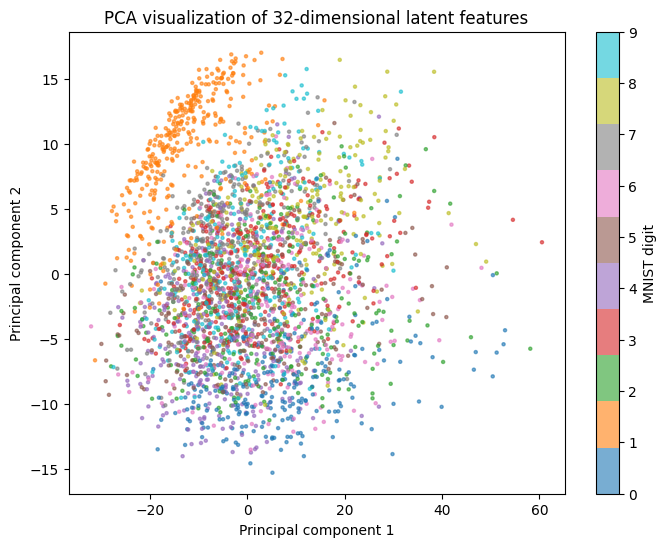

In [9]:
# Optional two-dimensional visualization using NumPy PCA (no scikit-learn required).
n_pca = 3000
features = latent_test[:n_pca]
centered = features - features.mean(axis=0, keepdims=True)
_, _, components = np.linalg.svd(centered, full_matrices=False)
latent_2d = centered @ components[:2].T

plt.figure(figsize=(8, 6))
scatter = plt.scatter(latent_2d[:, 0], latent_2d[:, 1], c=y_test[:n_pca], cmap="tab10", s=5, alpha=0.6)
plt.colorbar(scatter, ticks=range(10), label="MNIST digit")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("PCA visualization of 32-dimensional latent features")
plt.show()

In [10]:
# Save models and a small set of reconstructions for later inspection.
os.makedirs("autoencoder_outputs", exist_ok=True)
autoencoder.save("autoencoder_outputs/mnist_autoencoder.keras")
encoder.save("autoencoder_outputs/mnist_encoder.keras")
decoder.save("autoencoder_outputs/mnist_decoder.keras")
np.save("autoencoder_outputs/test_reconstructions.npy", reconstructed_test[:100])
print("Saved models and reconstructions in autoencoder_outputs/")

Saved models and reconstructions in autoencoder_outputs/
